In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# شكل موحّد لكل الرسوم
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
})
BLUE, ORANGE = "#2a78d6", "#eb6834"

os.makedirs("../images", exist_ok=True)
yearly = pd.read_csv("../data/clean/kingdom_yearly.csv")

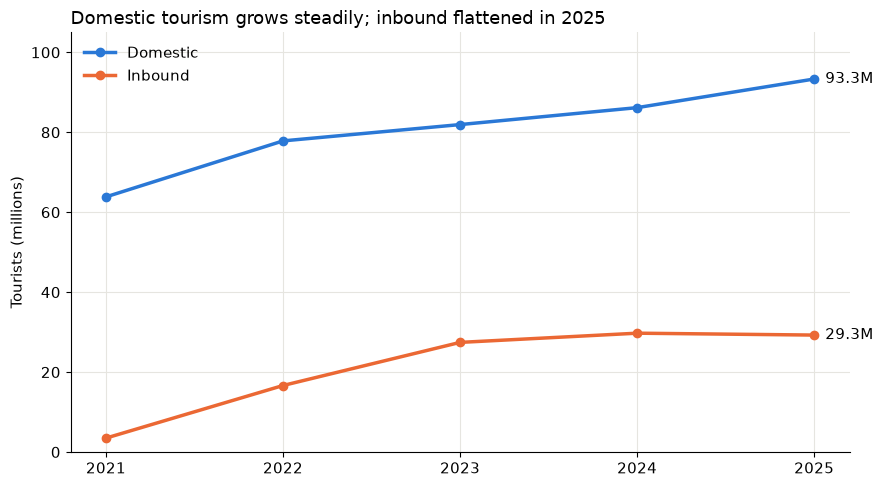

In [9]:
tourists = yearly[yearly["indicator"] == "Tourists Number (Overnight Visitors)"]

fig, ax = plt.subplots()
for tourism_type, color in [("Domestic", BLUE), ("Inbound", ORANGE)]:
    d = tourists[tourists["tourism_type"] == tourism_type]
    millions = d["value"] / 1000
    ax.plot(d["year"], millions, color=color, linewidth=2.5, marker="o", label=tourism_type)
    # نكتب آخر رقم جنب آخر نقطة
    ax.annotate(f"{millions.iloc[-1]:.1f}M", (d["year"].iloc[-1], millions.iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center")

ax.set_title("Domestic tourism grows steadily; inbound flattened in 2025", loc="left", fontsize=13)
ax.set_ylabel("Tourists (millions)")
ax.set_xticks([2021, 2022, 2023, 2024, 2025])
ax.set_ylim(0, 105)
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.savefig("../images/01_growth.png", dpi=150)
plt.show()

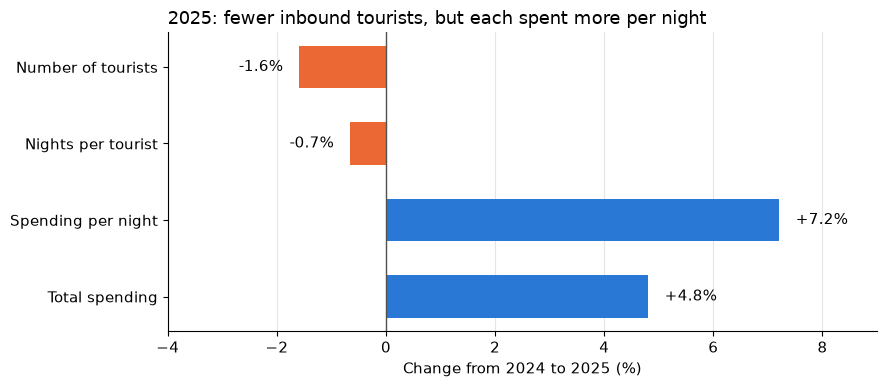

In [10]:
inbound = yearly[yearly["tourism_type"] == "Inbound"]

# نقلب الجدول: كل مؤشر صف، وكل سنة عمود
wide = inbound.pivot(index="indicator", columns="year", values="value")
change = (wide[2025] - wide[2024]) / wide[2024] * 100

# نختار 4 مؤشرات ونعطيها أسماء أقصر
labels = {
    "Tourists Number (Overnight Visitors)": "Number of tourists",
    "Average Length of Stay": "Nights per tourist",
    "Average Spending per Night": "Spending per night",
    "Tourists Spending": "Total spending",
}
change = change[list(labels)].rename(labels)

fig, ax = plt.subplots(figsize=(9, 4))
colors = [BLUE if v > 0 else ORANGE for v in change]
ax.barh(change.index, change.values, color=colors, height=0.55)
ax.axvline(0, color="#52514e", linewidth=1)

# نكتب النسبة جنب كل عمود
for i, v in enumerate(change.values):
    ax.text(v + (0.3 if v > 0 else -0.3), i, f"{v:+.1f}%", va="center",
            ha="left" if v > 0 else "right")

ax.invert_yaxis()
ax.set_xlim(-4, 9)
ax.grid(axis="y", visible=False)
ax.set_title("2025: fewer inbound tourists, but each spent more per night", loc="left", fontsize=13)
ax.set_xlabel("Change from 2024 to 2025 (%)")

plt.tight_layout()
plt.savefig("../images/02_spending_puzzle.png", dpi=150)
plt.show()

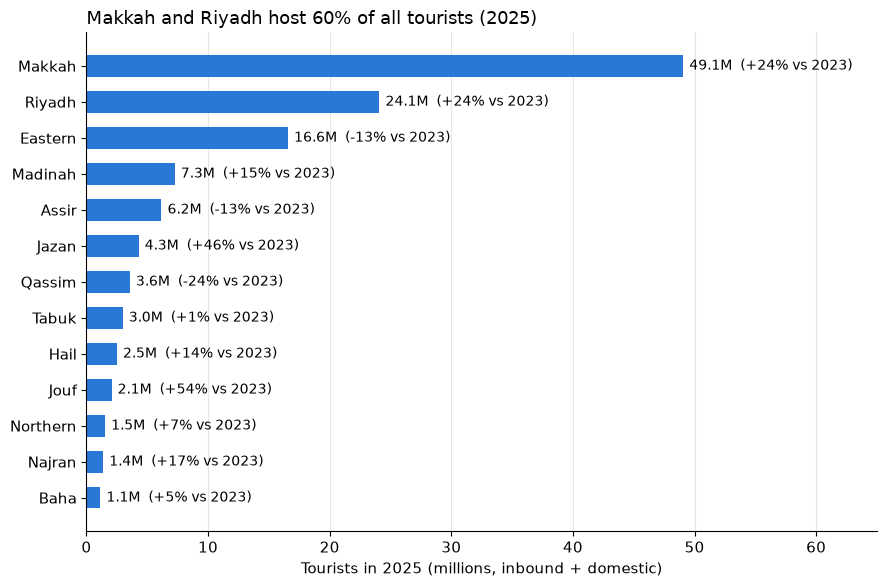

In [11]:
regions = pd.read_csv("../data/clean/regions_yearly.csv")

total = regions[(regions["indicator"] == "Tourists Number (Overnight Visitors)")
                & (regions["tourism_type"] == "Internal")]

r = total.pivot(index="region", columns="year", values="value")
r["millions_2025"] = r[2025] / 1000
r["growth_pct"] = (r[2025] - r[2023]) / r[2023] * 100
r = r.sort_values("millions_2025")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(r.index, r["millions_2025"], color=BLUE, height=0.6)

for i, (m, g) in enumerate(zip(r["millions_2025"], r["growth_pct"])):
    ax.text(m + 0.5, i, f"{m:.1f}M  ({g:+.0f}% vs 2023)", va="center", fontsize=10)

ax.set_xlim(0, 65)
ax.grid(axis="y", visible=False)
ax.set_title("Makkah and Riyadh host 60% of all tourists (2025)", loc="left", fontsize=13)
ax.set_xlabel("Tourists in 2025 (millions, inbound + domestic)")

plt.tight_layout()
plt.savefig("../images/03_regions.png", dpi=150)
plt.show()

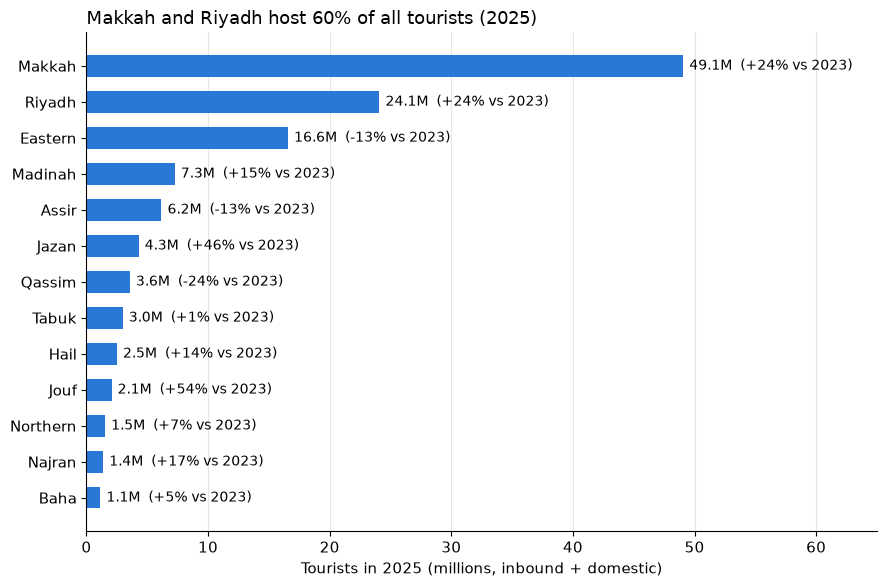

In [12]:
regions = pd.read_csv("../data/clean/regions_yearly.csv")

total = regions[(regions["indicator"] == "Tourists Number (Overnight Visitors)")
                & (regions["tourism_type"] == "Internal")]

r = total.pivot(index="region", columns="year", values="value")
r["millions_2025"] = r[2025] / 1000
r["growth_pct"] = (r[2025] - r[2023]) / r[2023] * 100
r = r.sort_values("millions_2025")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(r.index, r["millions_2025"], color=BLUE, height=0.6)

for i, (m, g) in enumerate(zip(r["millions_2025"], r["growth_pct"])):
    ax.text(m + 0.5, i, f"{m:.1f}M  ({g:+.0f}% vs 2023)", va="center", fontsize=10)

ax.set_xlim(0, 65)
ax.grid(axis="y", visible=False)
ax.set_title("Makkah and Riyadh host 60% of all tourists (2025)", loc="left", fontsize=13)
ax.set_xlabel("Tourists in 2025 (millions, inbound + domestic)")

plt.tight_layout()
plt.savefig("../images/03_regions.png", dpi=150)
plt.show()

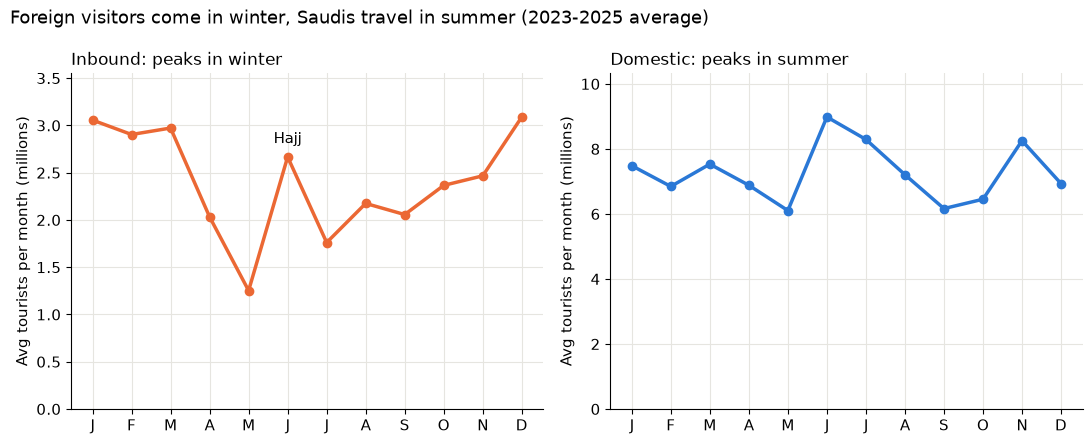

In [13]:
monthly = pd.read_csv("../data/clean/monthly.csv")
recent = monthly[monthly["year"] >= 2023]

# متوسط كل شهر على 3 سنوات، بالملايين
season = recent.groupby(["tourism_type", "month_num"])["tourists_000"].mean() / 1000

month_labels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

# لوحة فيها رسمتين جنب بعض
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (tourism_type, color, note) in zip(axes, [
        ("Inbound", ORANGE, "Inbound: peaks in winter"),
        ("Domestic", BLUE, "Domestic: peaks in summer")]):
    s = season[tourism_type]
    ax.plot(s.index, s.values, color=color, linewidth=2.5, marker="o")
    ax.set_title(note, loc="left", fontsize=12)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_labels)
    ax.set_ylim(0, s.max() * 1.15)
    ax.set_ylabel("Avg tourists per month (millions)")

# ملاحظة على قفزة يونيو
axes[0].annotate("Hajj", (6, season["Inbound"][6]), xytext=(0, 10),
                 textcoords="offset points", ha="center")

fig.suptitle("Foreign visitors come in winter, Saudis travel in summer (2023-2025 average)",
             x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.savefig("../images/04_seasonality.png", dpi=150)
plt.show()

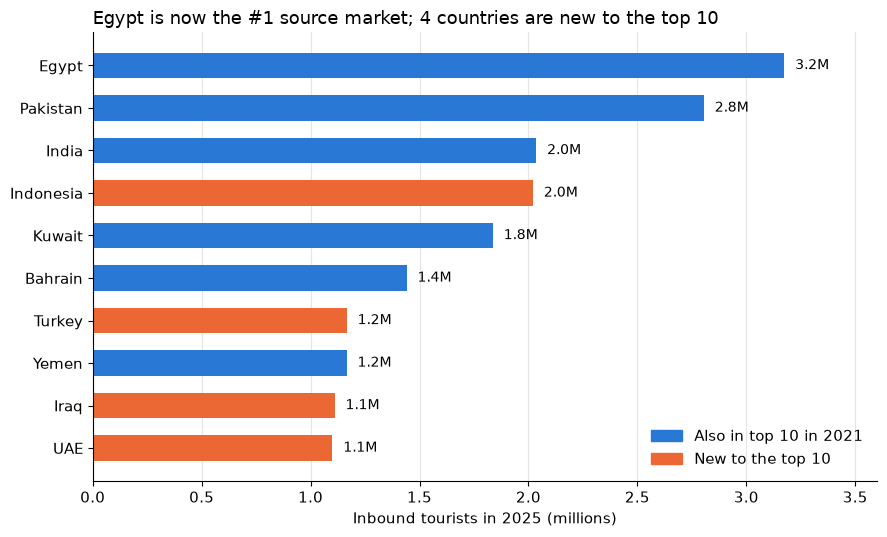

In [14]:
from matplotlib.patches import Patch

top10 = pd.read_csv("../data/clean/inbound_top10_countries.csv")
t25 = top10[top10["year"] == 2025].sort_values("tourists_000")

# دول 2021 في "مجموعة"، عشان نعرف مين الجديد
countries_2021 = set(top10[top10["year"] == 2021]["country"])
colors = [BLUE if c in countries_2021 else ORANGE for c in t25["country"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(t25["country"], t25["tourists_000"] / 1000, color=colors, height=0.6)

for i, v in enumerate(t25["tourists_000"] / 1000):
    ax.text(v + 0.05, i, f"{v:.1f}M", va="center", fontsize=10)

ax.set_xlim(0, 3.6)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=BLUE, label="Also in top 10 in 2021"),
                   Patch(color=ORANGE, label="New to the top 10")],
          frameon=False, loc="lower right")
ax.set_title("Egypt is now the #1 source market; 4 countries are new to the top 10",
             loc="left", fontsize=13)
ax.set_xlabel("Inbound tourists in 2025 (millions)")

plt.tight_layout()
plt.savefig("../images/05_top_countries.png", dpi=150)
plt.show()

In [ ]:
purpose = pd.read_csv("../data/clean/inbound_purpose.csv")

# مجموع كل سنة لكل غرض، والسنوات أعمدة
p = purpose.groupby(["purpose", "year"])["tourists_000"].sum().unstack()
p["change_pct"] = (p[2025] - p[2024]) / p[2024] * 100
p = p.sort_values("change_pct")

fig, ax = plt.subplots(figsize=(9, 4))
colors = [BLUE if v > 0 else ORANGE for v in p["change_pct"]]
ax.barh(p.index, p["change_pct"], color=colors, height=0.55)
ax.axvline(0, color="#52514e", linewidth=1)

for i, (v, n) in enumerate(zip(p["change_pct"], p[2025] / 1000)):
    ax.text(v + (1 if v > 0 else -1), i, f"{v:+.0f}%  ({n:.1f}M in 2025)", va="center",
            ha="left" if v > 0 else "right", fontsize=10)

ax.set_xlim(-50, 40)
ax.grid(axis="y", visible=False)
ax.set_title("Religious and business trips grew; family visits fell (2024 to 2025)",
             loc="left", fontsize=13)
ax.set_xlabel("Change in inbound tourists by purpose of visit (%)")

plt.tight_layout()
plt.savefig("../images/06_purpose.png", dpi=150)
plt.show()